# 4.1 — Non-uniform random numbers

Functions live in `functions.py`; this notebook runs them and keeps the data and figures.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from functions import *

In [2]:
# Parameters (quote these in the report captions)
SEED = 1
N = 100_000      # number of samples per distribution
BINS = 50        # number of histogram bins

rng = np.random.default_rng(SEED)
set_plot_style()
info = f"N = {N:,} samples, {BINS} bins, seed = {SEED}"

## (0) Why the inverse CDF method works

**Idea.** $F(x)$ tells you which fraction of the numbers should end up below $x$.
A uniform number $u$ ends up below the value $F(x)$ exactly a fraction $F(x)$ of the time.
So if we turn every $u$ into $x = F^{-1}(u)$, a fraction $F(x)$ of the results lands below $x$, which is exactly what we wanted.

In one line (the middle step works because $F$ only goes up):

$$P\big(F^{-1}(u) \le x\big) = P\big(u \le F(x)\big) = F(x).$$

**Recipe:** integrate $f$ to get $F$, write $u = F(x)$, and solve for $x$.

| we want | $F(x)$ | solve $u = F(x)$ for $x$ |
|---|---|---|
| uniform on $[-2,1]$: $f = 1/3$ | $(x+2)/3$ | $x = -2 + 3u$ |
| exponential: $f = e^{-x}$, $x\ge0$ | $1-e^{-x}$ | $x = -\log(1-u)$ |
| linear: $f = (x+1)/2$ on $[-1,1]$ | $(x+1)^2/4$ | $x = 2\sqrt{u} - 1$ |

## (a) Inverse CDF: uniform, exponential, linear

Use the three formulas from the table above. If they are right, the histograms lie on top of the black curves.

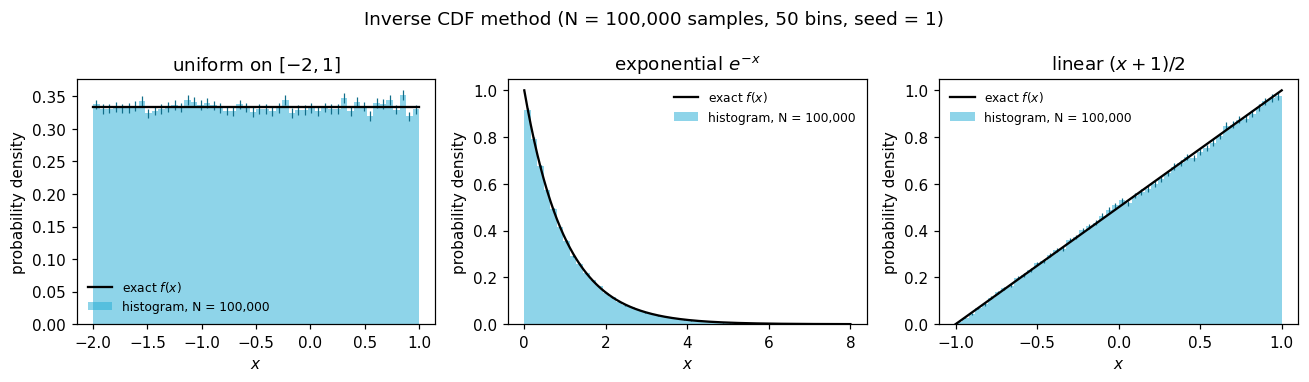

In [ ]:
x_uniform = sample_uniform(-2, 1, N, rng)
x_exp = sample_exponential(N, rng)
x_linear = sample_linear_inverse(N, rng)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

plot_density(axes[0], x_uniform, lambda x: uniform_pdf(x, -2, 1), (-2, 1), BINS, "uniform on $[-2,1]$")
plot_density(axes[1], x_exp, exponential_pdf, (0, 8), BINS, "exponential $e^{-x}$")
plot_density(axes[2], x_linear, linear_pdf, (-1, 1), BINS, "linear $(x+1)/2$")

fig.suptitle(f"Inverse CDF method ({info})")
fig.tight_layout()
save_figure(fig, "a_inverse_cdf")
plt.show()

## (b) Hit-and-miss: linear and $f(x) = -x(1-x)e^{-x^2}\log(1-x)$

**Idea.** Draw a box around the graph of $f$ and throw random points into it.
Keep only the points that land *under* the curve, and keep their $x$-value.
Where $f$ is high, more points fit under the curve, so more numbers come out there: exactly in proportion to $f$.

**In practice:** pick a random position $t$ in $[a,b]$ and a random height $s$ in $[0,M]$, and keep $t$ if $s \le f(t)$.
The height $M$ of the box must be at least as high as the top of $f$.

**How many points do we keep?** The area under the curve divided by the area of the box:
$\dfrac{\text{area under } f}{M\,(b-a)}$. All the other points are thrown away (wasted work), so the box should be as tight as possible.

The second function does not have area 1. Hit-and-miss does not care, because only the *shape* matters.
But to draw it on top of the histogram we divide it by its area $Z$.

In [5]:
# linear density on [-1, 1]: max f = 1 at x = 1
M_linear = find_bound(linear_pdf, -1, 1)
x_linear_hm, acc_linear = hit_and_miss(linear_pdf, -1, 1, M_linear, N, rng)

# the "weird" function on [0, 1]
Z = normalization(weird_function, 0, 1)
M_weird = find_bound(weird_function, 0, 1)
x_weird, acc_weird = hit_and_miss(weird_function, 0, 1, M_weird, N, rng)

print(f"linear: M = {M_linear:.3f}, acceptance = {acc_linear:.4f}, "
      f"theory 1/(M(b-a)) = {1 / (2 * M_linear):.4f}")
print(f"weird : Z = {Z:.5f}, M = {M_weird:.4f}, acceptance = {acc_weird:.4f}, "
      f"theory Z/(M(b-a)) = {Z / M_weird:.4f}")

linear: M = 1.050, acceptance = 0.4753, theory 1/(M(b-a)) = 0.4762
weird : Z = 0.09011, M = 0.1644, acceptance = 0.5494, theory Z/(M(b-a)) = 0.5480


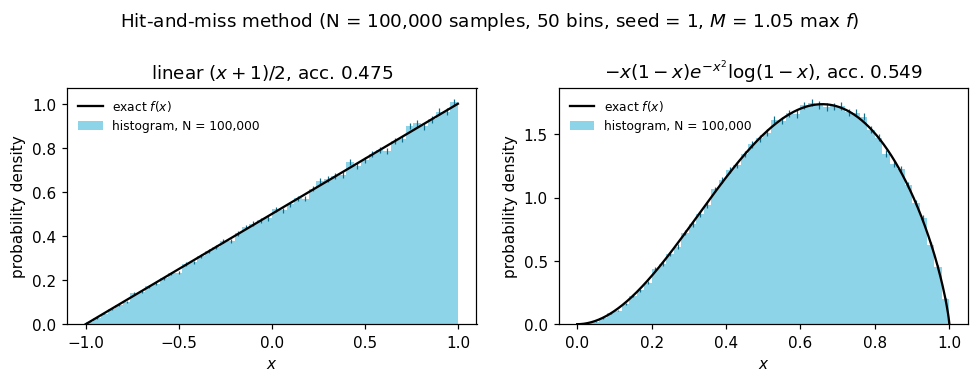

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_density(axes[0], x_linear_hm, linear_pdf, (-1, 1), BINS,
             f"linear $(x+1)/2$, acc. {acc_linear:.3f}")
plot_density(axes[1], x_weird, lambda x: weird_function(x) / Z, (0, 1), BINS,
             f"$-x(1-x)e^{{-x^2}}\\log(1-x)$, acc. {acc_weird:.3f}")
fig.suptitle(f"Hit-and-miss method ({info}, $M$ = 1.05 max $f$)")
fig.tight_layout()
save_figure(fig, "b_hit_and_miss")
plt.show()

## (c) Hit-and-miss: uniform points in the unit disk

Same idea in 2D: throw points in the square $[-1,1]\times[-1,1]$ and keep the ones inside the circle.
The fraction we keep should be (area of circle)/(area of square) $= \pi/4 \approx 0.785$.
Bonus: 4 times that fraction gives an estimate of $\pi$.

In [7]:
x_hm, y_hm, acc_disk = disk_hit_and_miss(N, rng)

# the acceptance is a binomial fraction, so its error is sqrt(p(1-p)/n_tried)
n_tried = N / acc_disk
err_disk = np.sqrt(acc_disk * (1 - acc_disk) / n_tried)
print(f"acceptance = {acc_disk:.4f} ± {err_disk:.4f},  pi/4 = {np.pi / 4:.4f}")
print(f"so pi is estimated as {4 * acc_disk:.4f} ± {4 * err_disk:.4f}")

acceptance = 0.7854 ± 0.0012,  pi/4 = 0.7854
so pi is estimated as 3.1416 ± 0.0046


## (d) Uniform disk without hit-and-miss (polar coordinates)

Now pick each point directly as an angle $\theta$ and a distance $r$ from the centre.

- **Angle:** every direction is equally likely, so $\theta$ is uniform in $[0, 2\pi]$.
- **Distance:** taking $r$ uniform in $[0,1]$ is **wrong**. A circle at distance $r$ has length $2\pi r$,
  so there is more room far from the centre than close to it. The number of points at distance $r$ should therefore grow like $r$:
  $f(r) = 2r$ (the 2 makes the total area 1).
  Then $F(r) = r^2$, and the inverse CDF trick gives $r = \sqrt{u}$.

(Same thing written as a formula: the area element is $dA = r\,dr\,d\theta$, so $f(r,\theta) = \frac{r}{\pi} = 2r\cdot\frac{1}{2\pi}$.)

The right panel uses the wrong $r = u$ on purpose, to show what goes wrong.

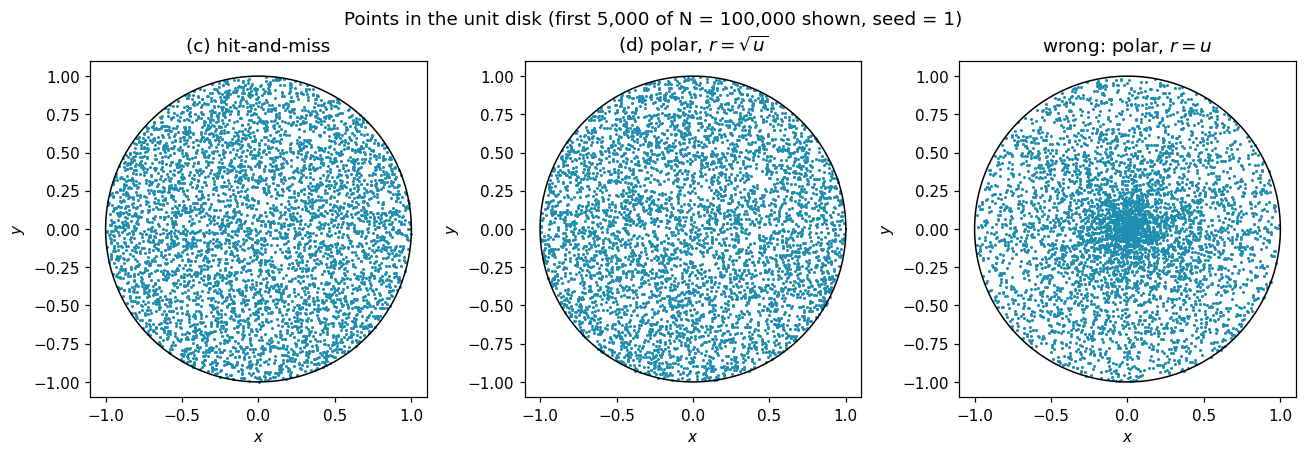

In [8]:
x_pol, y_pol = disk_polar(N, rng)
x_naive, y_naive = disk_polar_naive(N, rng)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
plot_disk(axes[0], x_hm, y_hm, f"(c) hit-and-miss")
plot_disk(axes[1], x_pol, y_pol, r"(d) polar, $r=\sqrt{u}$")
plot_disk(axes[2], x_naive, y_naive, r"wrong: polar, $r=u$")
fig.suptitle(f"Points in the unit disk (first 5,000 of N = {N:,} shown, seed = {SEED})")
fig.tight_layout()
save_figure(fig, "cd_disk_scatter")
plt.show()

The scatter plots show the difference by eye. To see it more precisely, make a histogram of the distances $r$:
for points spread evenly over the disk it should follow the line $2r$.

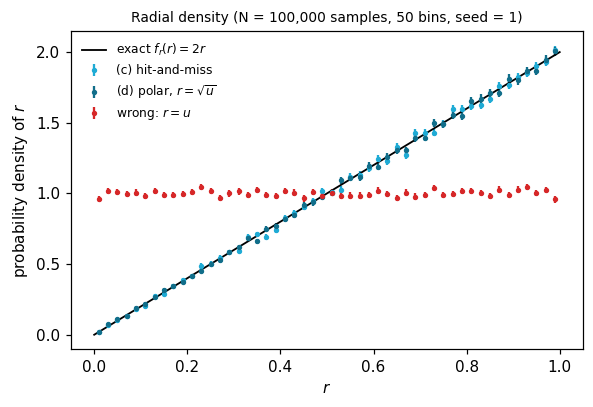

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for (x, y), label, colour in [((x_hm, y_hm), "(c) hit-and-miss", KUL_BLUES[0]),
                              ((x_pol, y_pol), r"(d) polar, $r=\sqrt{u}$", KUL_BLUES[2]),
                              ((x_naive, y_naive), r"wrong: $r=u$", "tab:red")]:
    r = np.sqrt(x**2 + y**2)
    centres, density, error, _ = density_histogram(r, BINS, (0, 1))
    ax.errorbar(centres, density, yerr=error, fmt="o", ms=2.5, color=colour, label=label)

r_line = np.linspace(0, 1, 100)
ax.plot(r_line, 2 * r_line, "k", lw=1.2, label="exact $f_r(r) = 2r$")
ax.set_xlabel("$r$")
ax.set_ylabel("probability density of $r$")
ax.set_title(f"Radial density ({info})", fontsize=9)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "cd_radial_density")
plt.show()